In [1]:
import numpy as np
import matplotlib.pyplot as plt

# Generate a dataset of points uniformly distributed in [-1.5, 1.5]^2
np.random.seed(0)
N = 1000
X = np.random.uniform(-1.5, 1.5, (N, 2))

# Class 1 = points inside the triangle with vertices (0, 1), (-1, -0.7), (1, -0.7)
def inside_triangle(X):
    x1, x2 = X[:, 0], X[:, 1]
    return ((x2 + 0.7 >= 0) & (1.7 * x1 - x2 + 1 >= 0) & (-1.7 * x1 - x2 + 1 >= 0)).astype(int)

y = inside_triangle(X)


In [2]:
def heaviside(t):
    return (t >= 0).astype(float)

# First layer: one row of W1 for each neuron (i.e. for each edge of the triangle)
W1 = np.array([[0.0, 1.0],
               [1.7, -1.0],
               [-1.7, -1.0]])
b1 = np.array([0.7, 1.0, 1.0])

# Second layer: AND of the three hidden neurons
W2 = np.array([[1.0, 1.0, 1.0]])
b2 = np.array([-2.5])

def hand_made_network(X):
    h = heaviside(X @ W1.T + b1)     # shape (N, 3)
    y_hat = heaviside(h @ W2.T + b2) # shape (N, 1)
    return h, y_hat[:, 0]

h, y_hat = hand_made_network(X)
print(f"Accuracy of the hand-made network: {np.mean(y_hat == y) * 100:.2f}%")

Accuracy of the hand-made network: 100.00%


In [3]:
def relu(z):
    return np.maximum(0, z)

def relu_prime(z):
    return (z > 0).astype(float)

def softmax(z):
    z = z - z.max(axis=1, keepdims=True)  # For numerical stability
    e = np.exp(z)
    return e / e.sum(axis=1, keepdims=True)

def init_params(sizes, seed=0):
    """
    sizes: list [n_0, n_1, ..., n_L] with the width of each layer.
    Returns a list of [W, b] pairs, with W of shape (n_l, n_{l-1}).
    """
    rng = np.random.default_rng(seed)
    params = []
    for n_in, n_out in zip(sizes[:-1], sizes[1:]):
        W = rng.normal(0, np.sqrt(2 / n_in), (n_out, n_in))  # He initialization
        b = np.zeros(n_out)
        params.append([W, b])
    return params

def forward(params, X):
    """
    Forward pass. X has shape (N, d).
    Returns the predicted probabilities Y_hat (N, K), and the list of
    intermediate values [(Z^l, H^l)], needed for the backward pass.
    """
    H = X
    cache = [(None, X)]
    for l, (W, b) in enumerate(params):
        Z = H @ W.T + b
        H = softmax(Z) if l == len(params) - 1 else relu(Z)
        cache.append((Z, H))
    return H, cache

def cross_entropy(Y_hat, Y):
    return -np.mean(np.sum(Y * np.log(Y_hat + 1e-12), axis=1))

def backward(params, cache, Y):
    """
    Backward pass. Returns the gradient of the average Cross-Entropy
    with respect to each [W, b], with the same structure of params.
    """
    N = Y.shape[0]
    grads = [None] * len(params)
    Delta = (cache[-1][1] - Y) / N           # Delta^L = (Y_hat - Y) / N
    for l in reversed(range(len(params))):
        W, b = params[l]
        H_prev = cache[l][1]                 # H^{l-1}
        grads[l] = [Delta.T @ H_prev, Delta.sum(axis=0)]
        if l > 0:
            Delta = (Delta @ W) * relu_prime(cache[l][0])  # Delta^{l-1}
    return grads

In [4]:
# A small network: 2 inputs -> 5 hidden -> 4 hidden -> 3 classes
sizes = [2, 5, 4, 3]
params = init_params(sizes, seed=1)

# Random data and one-hot labels
rng = np.random.default_rng(0)
X_small = rng.normal(0, 1, (10, 2))
Y_small = np.eye(3)[rng.integers(0, 3, 10)]

# Gradient via backpropagation
Y_hat, cache = forward(params, X_small)
grads = backward(params, cache, Y_small)

# Gradient via (centered) finite differences
eps = 1e-6
max_err = 0
for l in range(len(params)):
    for p, g in zip(params[l], grads[l]):
        for idx in np.ndindex(p.shape):
            old = p[idx]
            p[idx] = old + eps
            L_plus = cross_entropy(forward(params, X_small)[0], Y_small)
            p[idx] = old - eps
            L_minus = cross_entropy(forward(params, X_small)[0], Y_small)
            p[idx] = old
            fd = (L_plus - L_minus) / (2 * eps)
            max_err = max(max_err, abs(fd - g[idx]))

print(f"Maximum difference between backprop and finite differences: {max_err:.2e}")

Maximum difference between backprop and finite differences: 1.74e-10


In [5]:
# One-hot encoding of the labels (K = 2 classes)
Y = np.eye(2)[y]

params = init_params([2, 16, 16, 2], seed=0)
Y_hat, _ = forward(params, X)

print(f"Loss of the untrained network: {cross_entropy(Y_hat, Y):.4f}")
print(f"Accuracy of the untrained network: {np.mean(Y_hat.argmax(axis=1) == y) * 100:.2f}%")

Loss of the untrained network: 1.1963
Accuracy of the untrained network: 18.40%


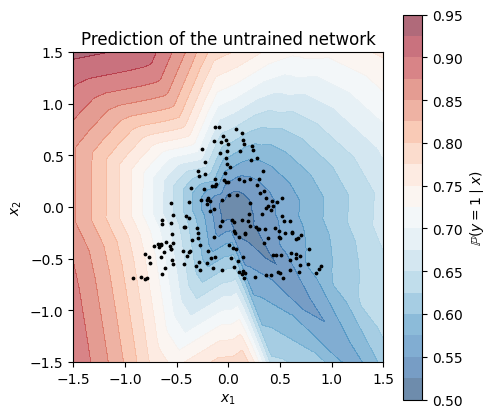

In [6]:
xx1, xx2 = np.meshgrid(np.linspace(-1.5, 1.5, 300), np.linspace(-1.5, 1.5, 300))
grid = np.stack([xx1.ravel(), xx2.ravel()], axis=1)

P_grid, _ = forward(params, grid)
plt.figure(figsize=(5, 5))
plt.contourf(xx1, xx2, P_grid[:, 1].reshape(xx1.shape), levels=20, cmap="RdBu_r", alpha=0.6)
plt.colorbar(label=r"$\mathbb{P}(y = 1 \mid x)$")
plt.scatter(X[y == 1, 0], X[y == 1, 1], s=3, c="k")
plt.title("Prediction of the untrained network")
plt.gca().set_aspect("equal")
plt.xlabel("$x_1$")
plt.ylabel("$x_2$")
plt.show()